# Thị trường crypto 2020–2026: rủi ro, đa dạng hoá và quy tắc giao dịch đơn giản

**Câu hỏi của nhà đầu tư:** một quỹ hoặc nhà đầu tư cá nhân muốn phân bổ một phần tài sản vào crypto. Họ cần biết:

1. Rủi ro thật sự của crypto lớn đến đâu (biến động, sụt giảm tối đa, ngày tệ nhất)?
2. Mua nhiều đồng (đa dạng hoá) có tốt hơn chỉ giữ Bitcoin không?
3. Có quy tắc đơn giản, kiểm chứng được nào giúp giảm sụt giảm mà không mất nhiều lợi nhuận?
4. Dữ liệu on-chain (MVRV) có nói được giá đang rẻ hay đắt không?

**Dữ liệu:** Coin Metrics Community Data (giá đóng cửa ngày theo USD và chỉ số on-chain), 9 đồng coin lớn có đủ dữ liệu từ 01/09/2020 đến 23/05/2026, cộng lịch sử Bitcoin từ 2010.

**Công cụ:** Python, pandas, numpy, matplotlib.

## 1. Chuẩn bị

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.font_manager as fm
import glob, os

os.makedirs('figures', exist_ok=True)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# Style tối giản: nền trắng, 1 màu nhấn navy, còn lại là xám
NAVY, GREY, LIGHT, RED = '#1F3A5F', '#8A94A6', '#D5DAE1', '#B3261E'
for f in glob.glob('fonts/*.ttf'):
    fm.fontManager.addfont(f)
if 'IBM Plex Sans' in {f.name for f in fm.fontManager.ttflist}:
    plt.rcParams['font.family'] = 'IBM Plex Sans'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#9AA3B2',
                     'axes.titleweight': 'semibold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#ECEFF3', 'grid.linewidth': 0.8, 'figure.dpi': 100})

In [2]:
prices = pd.read_csv('data/crypto_prices.csv', parse_dates=['date'], index_col='date')
btc_chain = pd.read_csv('data/btc_onchain.csv', parse_dates=['date'], index_col='date')

In [3]:
print(prices.shape, btc_chain.shape)
prices.tail()

(2103, 11) (5789, 6)


,BTC,ETH,BNB,XRP,ADA,DOGE,LINK,LTC,DOT,USDT_cap,USDC_cap
date,,,,,,,,,,,
2026-05-19,"76,807.461","2,112.008",639.761,1.361,0.249,0.103,9.457,54.356,1.225,"192,835,000,224.425","73,606,475,119.487"
2026-05-20,"77,408.172","2,125.169",648.317,1.364,0.249,0.103,9.610,53.873,1.246,"192,822,384,355.919","73,275,500,967.810"
2026-05-21,"77,595.386","2,132.135",657.403,1.372,0.250,0.105,9.730,54.138,1.289,"192,825,353,279.231","73,314,830,464.294"
2026-05-22,"75,567.543","2,066.767",650.158,1.336,0.243,0.103,9.457,52.900,1.267,"192,778,987,617.921","72,700,466,168.226"
2026-05-23,"76,619.867","2,116.168",655.775,1.358,0.246,0.103,9.556,53.440,1.291,"192,764,466,941.011","72,541,750,173.073"


## 2. Kiểm tra và làm sạch dữ liệu

Các điểm cần kiểm tra: ngày bị thiếu (crypto giao dịch cả cuối tuần nên phải đủ 365 ngày/năm), giá trống hoặc bằng 0, và các ngày biến động bất thường có phải lỗi dữ liệu không.

In [4]:
COINS = ['BTC', 'ETH', 'BNB', 'XRP', 'ADA', 'DOGE', 'LINK', 'LTC', 'DOT']

print('Số ngày bị thiếu:', (prices.index.to_series().diff() != pd.Timedelta('1D')).sum() - 1)
print('Giá trống:', prices[COINS].isna().sum().sum(), '| Giá <= 0:', (prices[COINS] <= 0).sum().sum())
print('Ngày đầu có đủ 9 coin:', prices[COINS].dropna().index.min().date())

# Chọn giai đoạn phân tích: từ 01/09/2020 (DOT có giá từ 20/08/2020)
px = prices.loc['2020-09-01':, COINS]
ret = px.pct_change().dropna()
print(f'Giai đoạn: {ret.index.min().date()} -> {ret.index.max().date()}, {len(ret):,} ngày')

Số ngày bị thiếu: 0
Giá trống: 0 | Giá <= 0: 0
Ngày đầu có đủ 9 coin: 2020-08-20
Giai đoạn: 2020-09-02 -> 2026-05-23, 2,090 ngày


In [5]:
# Ngày tăng/giảm trên 40%: có phải lỗi?
big = ret.stack()
big = big[big.abs() > 0.4].rename('return').reset_index()
big.columns = ['date', 'coin', 'return']
big.sort_values('date')

,date,coin,return
0,2020-11-21,XRP,0.407
1,2020-12-23,XRP,-0.406
2,2021-01-02,DOGE,0.892
3,2021-01-28,DOGE,3.084
4,2021-01-29,DOGE,0.592
5,2021-01-30,XRP,0.527
6,2021-01-30,DOGE,-0.402
7,2021-02-04,DOGE,0.455
8,2021-02-19,BNB,0.717
9,2021-04-05,XRP,0.428


Các ngày biến động cực lớn đều trùng với sự kiện có thật: DOGE tăng 308% ngày 28/01/2021 theo làn sóng mạng xã hội, XRP giảm 41% khi SEC kiện Ripple (23/12/2020) và tăng 73% khi thắng kiện một phần (13/07/2023), ADA tăng 69% khi được nhắc tên trong kế hoạch dự trữ crypto của Mỹ (02/03/2025). Đây là đặc điểm của thị trường, không phải lỗi, nên **giữ lại**.

**Lưu ý thiên lệch sống sót (survivorship bias):** 9 đồng được chọn vì vẫn còn lớn và có dữ liệu đến 2026. Những đồng đã sụp đổ (LUNA, FTT...) không có trong mẫu, nên kết quả của rổ altcoin dưới đây có khả năng **đẹp hơn thực tế**.

## 3. Bức tranh chung: 1 USD đầu tư năm 2020 giờ còn bao nhiêu?

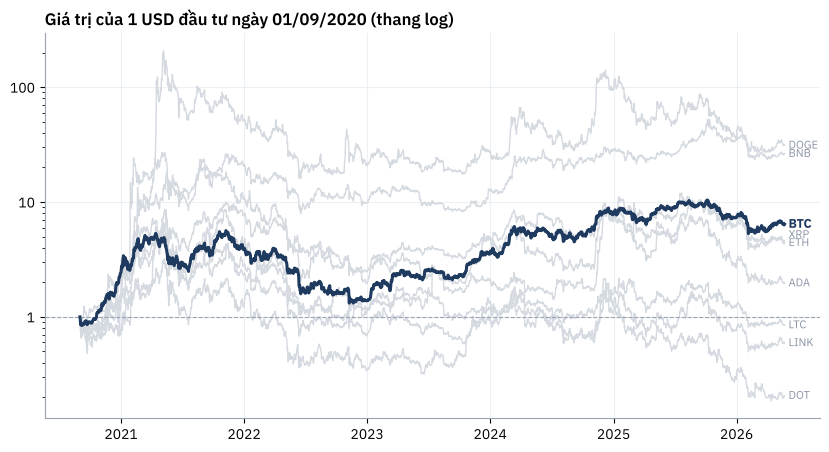

In [6]:
growth = px / px.iloc[0]
# Vị trí nhãn cuối đường: giãn ra để không đè lên nhau (tính trên thang log)
last = np.log10(growth.iloc[-1]).sort_values()
label_y = last.copy()
for i in range(1, len(label_y)):
    label_y.iloc[i] = max(label_y.iloc[i], label_y.iloc[i - 1] + 0.07)

fig, ax = plt.subplots(figsize=(10, 5))
for coin in COINS:
    is_btc = coin == 'BTC'
    ax.plot(growth.index, growth[coin], color=NAVY if is_btc else LIGHT, lw=2.2 if is_btc else 1,
            zorder=3 if is_btc else 2)
    ax.text(growth.index[-1] + pd.Timedelta(days=12), 10 ** label_y[coin], coin, va='center',
            color=NAVY if is_btc else GREY, fontsize=9 if is_btc else 8,
            fontweight='bold' if is_btc else 'normal')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: f'{y:g}'))
ax.axhline(1, color='#9AA3B2', lw=0.8, ls='--')
ax.set_title('Giá trị của 1 USD đầu tư ngày 01/09/2020 (thang log)')
plt.savefig('figures/growth.png', dpi=200, bbox_inches='tight')
plt.show()

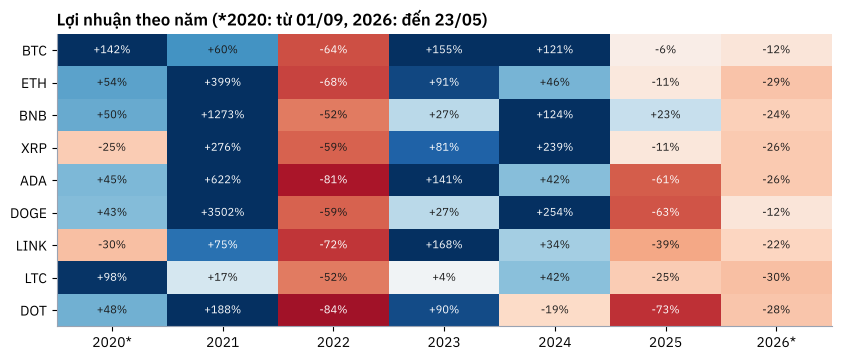

In [7]:
yearly = px.resample('YE').last()
yearly = pd.concat([px.iloc[[0]], yearly]).pct_change().dropna()
yearly.index = [str(d.year) + ('*' if d.year in (2020, 2026) else '') for d in yearly.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
vals = yearly.T.values * 100
im = ax.imshow(np.clip(vals, -100, 150), cmap='RdBu', vmin=-100, vmax=100, aspect='auto')
ax.set_xticks(range(len(yearly)), yearly.index)
ax.set_yticks(range(len(COINS)), COINS)
ax.grid(False)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        ax.text(j, i, f'{v:+.0f}%', ha='center', va='center', fontsize=8,
                color='white' if abs(v) > 60 else '#1A1A1A')
ax.set_title('Lợi nhuận theo năm (*2020: từ 01/09, 2026: đến 23/05)')
plt.savefig('figures/yearly.png', dpi=200, bbox_inches='tight')
plt.show()

**Nhận xét:**
- Sau gần 6 năm, BTC tăng khoảng 6,4 lần. Chỉ 2 đồng vượt xa BTC là **BNB** và **DOGE**; ETH, XRP, ADA kém hơn; **LINK, LTC, DOT còn lỗ**.
- Gần như toàn bộ phần vượt trội của altcoin nằm ở **năm 2021** (DOGE +3.500%, BNB +1.270%). Từ 2022 trở đi, BTC tốt hơn đa số altcoin gần như mọi năm.
- Năm 2022, cả 9 đồng đều giảm 52–84%: khi thị trường sập, không có đồng nào "trú ẩn" được.

## 4. Rủi ro: biến động, sụt giảm tối đa, ngày tệ nhất

In [8]:
def perf(r):
    """Các chỉ số hiệu quả từ chuỗi lợi nhuận ngày. Crypto giao dịch 365 ngày/năm."""
    equity = (1 + r).cumprod()
    years = len(r) / 365
    return pd.Series({
        'Tổng lợi nhuận': equity.iloc[-1] - 1,
        'CAGR': equity.iloc[-1] ** (1 / years) - 1,
        'Biến động năm': r.std() * np.sqrt(365),
        'Sharpe (rf=0)': r.mean() / r.std() * np.sqrt(365),
        'Sụt giảm tối đa': (equity / equity.cummax() - 1).min(),
        'VaR 95% (1 ngày)': r.quantile(0.05),
        'Ngày tệ nhất': r.min(),
    })

beta = ret.cov()['BTC'] / ret['BTC'].var()
risk = ret.apply(perf).T
risk['Beta với BTC'] = beta
risk.sort_values('Sharpe (rf=0)', ascending=False)

,Tổng lợi nhuận,CAGR,Biến động năm,Sharpe (rf=0),Sụt giảm tối đa,VaR 95% (1 ngày),Ngày tệ nhất,Beta với BTC
BNB,25.348,0.771,0.817,1.087,-0.707,-0.057,-0.297,0.887
DOGE,30.105,0.823,1.817,0.893,-0.923,-0.075,-0.402,1.298
BTC,5.401,0.383,0.575,0.851,-0.767,-0.044,-0.168,1.000
XRP,3.577,0.304,1.046,0.746,-0.832,-0.066,-0.406,0.995
ETH,3.402,0.295,0.777,0.721,-0.794,-0.062,-0.247,1.088
ADA,0.964,0.125,0.971,0.587,-0.920,-0.068,-0.232,1.105
LINK,-0.407,-0.087,0.991,0.403,-0.901,-0.080,-0.340,1.166
LTC,-0.153,-0.029,0.846,0.392,-0.889,-0.067,-0.334,1.049
DOT,-0.794,-0.241,0.987,0.207,-0.978,-0.074,-0.351,1.139


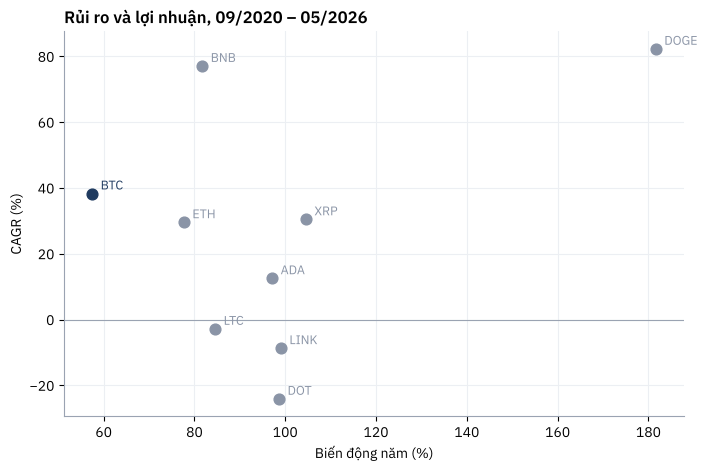

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for coin, row in risk.iterrows():
    color = NAVY if coin == 'BTC' else GREY
    ax.scatter(row['Biến động năm'] * 100, row['CAGR'] * 100, s=60, color=color, zorder=3)
    ax.annotate(coin, (row['Biến động năm'] * 100, row['CAGR'] * 100), xytext=(6, 3),
                textcoords='offset points', fontsize=9, color=color)
ax.axhline(0, color='#9AA3B2', lw=0.8)
ax.set_xlabel('Biến động năm (%)')
ax.set_ylabel('CAGR (%)')
ax.set_title('Rủi ro và lợi nhuận, 09/2020 – 05/2026')
plt.savefig('figures/risk_return.png', dpi=200, bbox_inches='tight')
plt.show()

**Nhận xét:**
- BTC có biến động thấp nhất nhóm (khoảng 58%/năm, gấp 3–4 lần cổ phiếu) nhưng vẫn từng **sụt 77%** từ đỉnh. Các altcoin sụt 70–98%.
- Altcoin có beta với BTC khoảng 1,0–1,3: BTC giảm 10% thì altcoin thường giảm 10–13%.
- VaR 95% của BTC khoảng -4,4%: cứ 20 ngày thì có 1 ngày lỗ hơn 4,4%.
- Biến động cao hơn **không** đi kèm lợi nhuận cao hơn: ADA, LINK, LTC, DOT rủi ro hơn BTC nhưng lợi nhuận thấp hơn nhiều.

## 5. Đa dạng hoá có giảm rủi ro không?

In [10]:
corr = ret.corr()
alts = [c for c in COINS if c != 'BTC']

# Tương quan với BTC trong ngày BTC giảm mạnh (10% ngày tệ nhất), ngày bình thường và ngày tăng mạnh
q10, q90 = ret['BTC'].quantile([0.1, 0.9])
regimes = {'BTC giảm mạnh': ret[ret['BTC'] < q10],
           'Bình thường': ret[(ret['BTC'] >= q10) & (ret['BTC'] <= q90)],
           'BTC tăng mạnh': ret[ret['BTC'] > q90]}
regime_corr = pd.Series({k: v[alts].corrwith(v['BTC']).mean() for k, v in regimes.items()})
print('Tương quan trung bình altcoin - BTC:')
print(regime_corr.round(2))

Tương quan trung bình altcoin - BTC:
BTC giảm mạnh   0.570
Bình thường     0.460
BTC tăng mạnh   0.310
dtype: float64


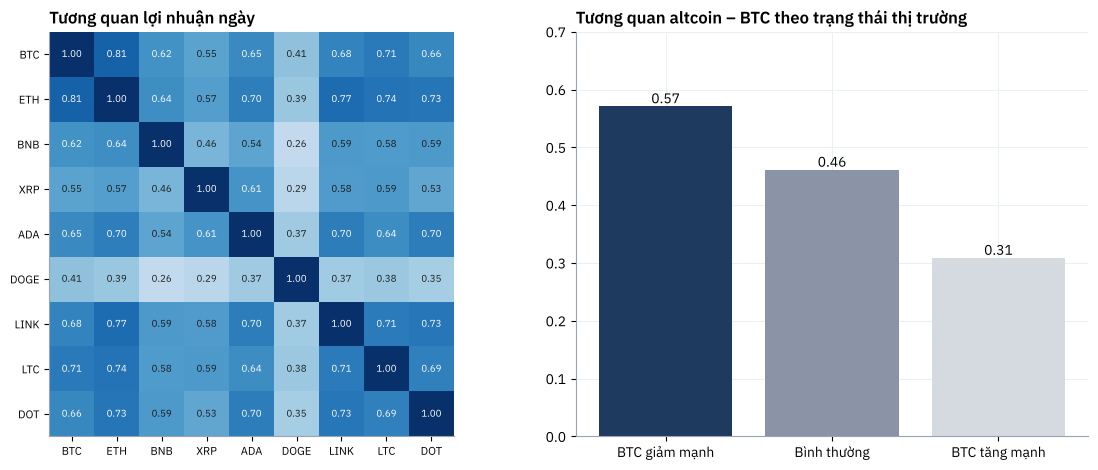

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
ax.imshow(corr, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(COINS)), COINS, fontsize=8)
ax.set_yticks(range(len(COINS)), COINS, fontsize=8)
ax.grid(False)
for i in range(len(COINS)):
    for j in range(len(COINS)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if corr.iloc[i, j] > 0.6 else '#1A1A1A')
ax.set_title('Tương quan lợi nhuận ngày')

ax = axes[1]
bars = ax.bar(regime_corr.index, regime_corr.values, color=[NAVY, GREY, LIGHT])
ax.bar_label(bars, fmt='%.2f')
ax.set_ylim(0, 0.7)
ax.set_title('Tương quan altcoin – BTC theo trạng thái thị trường')
plt.tight_layout()
plt.savefig('figures/correlation.png', dpi=200, bbox_inches='tight')
plt.show()

Tương quan trung bình giữa các altcoin khoảng 0,56, và **tăng lên 0,57 vào những ngày BTC giảm mạnh** (so với 0,31 ngày BTC tăng mạnh). Nghĩa là đa dạng hoá trong crypto hoạt động kém nhất đúng lúc cần nó nhất. DOGE là ngoại lệ có tương quan thấp (0,41), vì giá chạy theo mạng xã hội hơn là theo thị trường chung.

Tiếp theo, so sánh 3 danh mục tái cân bằng hằng tháng: chỉ BTC, chia đều 9 đồng (EW9), và chia đều 7 đồng bỏ BNB và DOGE (EW7), với các ngày bắt đầu khác nhau.

In [12]:
def rebalanced(weights, r):
    """Lợi nhuận ngày của danh mục tái cân bằng về tỷ trọng mục tiêu đầu mỗi tháng."""
    w = pd.Series(weights)
    values, level = [], 1.0
    for _, month in r.groupby(r.index.to_period('M')):
        holding = w * level
        for _, row in month.iterrows():
            holding = holding * (1 + row[w.index])
            values.append(holding.sum())
        level = values[-1]
    v = pd.Series(values, index=r.index)
    return v.pct_change().fillna(v.iloc[0] - 1)

portfolios = {
    'Chỉ BTC': {'BTC': 1.0},
    'EW9 (9 đồng)': {c: 1 / 9 for c in COINS},
    'EW7 (bỏ BNB, DOGE)': {c: 1 / 7 for c in COINS if c not in ('BNB', 'DOGE')},
}
starts = ['2020-09-01', '2021-06-01', '2022-01-01', '2023-01-01']
rows = []
for start in starts:
    r = ret.loc[start:]
    for name, w in portfolios.items():
        p = perf(rebalanced(w, r))
        rows.append({'Bắt đầu': start, 'Danh mục': name, **p})
basket = pd.DataFrame(rows)
basket.pivot(index='Bắt đầu', columns='Danh mục', values='CAGR')

Danh mục,Chỉ BTC,"EW7 (bỏ BNB, DOGE)",EW9 (9 đồng)
Bắt đầu,,,
2020-09-01,0.383,0.256,0.508
2021-06-01,0.155,-0.099,-0.063
2022-01-01,0.121,-0.107,-0.063
2023-01-01,0.571,0.210,0.245


In [13]:
basket.pivot(index='Bắt đầu', columns='Danh mục', values='Sụt giảm tối đa')

Danh mục,Chỉ BTC,"EW7 (bỏ BNB, DOGE)",EW9 (9 đồng)
Bắt đầu,,,
2020-09-01,-0.767,-0.804,-0.792
2021-06-01,-0.767,-0.804,-0.784
2022-01-01,-0.669,-0.702,-0.680
2023-01-01,-0.491,-0.647,-0.631


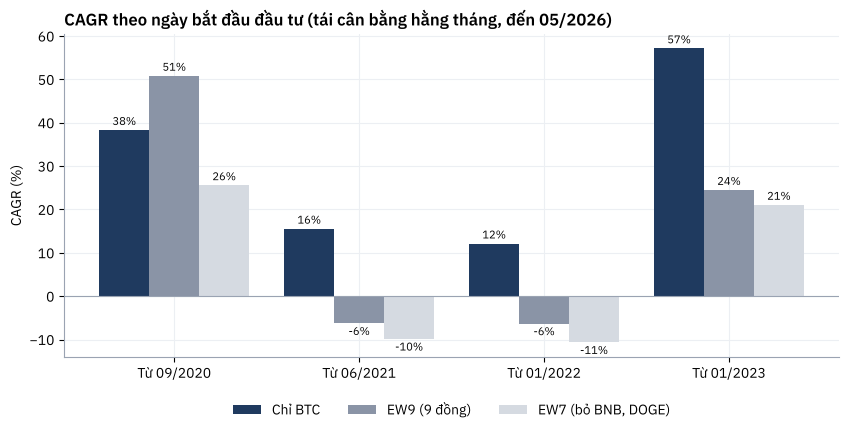

In [14]:
cagr_tbl = basket.pivot(index='Bắt đầu', columns='Danh mục', values='CAGR')[list(portfolios)]
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(cagr_tbl))
for i, (name, color) in enumerate(zip(cagr_tbl.columns, [NAVY, GREY, LIGHT])):
    b = ax.bar(x + (i - 1) * 0.27, cagr_tbl[name] * 100, 0.27, label=name, color=color)
    ax.bar_label(b, fmt='%.0f%%', fontsize=8, padding=2)
ax.set_xticks(x, ['Từ ' + pd.Timestamp(s).strftime('%m/%Y') for s in cagr_tbl.index])
ax.axhline(0, color='#9AA3B2', lw=0.8)
ax.set_ylabel('CAGR (%)')
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
ax.set_title('CAGR theo ngày bắt đầu đầu tư (tái cân bằng hằng tháng, đến 05/2026)')
plt.savefig('figures/baskets.png', dpi=200, bbox_inches='tight')
plt.show()

**Nhận xét:**
- Nếu bắt đầu từ 09/2020, rổ 9 đồng thắng BTC (CAGR ~51% so với ~38%). Nhưng phần thắng đến **hoàn toàn từ BNB và DOGE**: bỏ 2 đồng này, rổ còn lại chỉ đạt ~26%, thua BTC.
- Chỉ cần bắt đầu muộn hơn 9 tháng (06/2021) hoặc bất kỳ mốc nào sau đó, **BTC thắng mọi rổ** cả về lợi nhuận lẫn sụt giảm.
- Kết luận: đa dạng hoá sang altcoin là đặt cược vào việc chọn trúng vài đồng thắng lớn, không phải cách giảm rủi ro. Cộng thêm thiên lệch sống sót, kết quả thực tế còn kém hơn.

## 6. Quy tắc đơn giản: chỉ giữ BTC khi giá trên đường trung bình 200 ngày

**Quy tắc:** cuối mỗi ngày, nếu giá đóng cửa BTC lớn hơn trung bình 200 ngày thì giữ BTC trong ngày hôm sau, ngược lại giữ tiền mặt (USD, lãi 0%). Mỗi lần mua/bán chịu phí 0,1%. Tín hiệu được dịch 1 ngày (`shift(1)`) để không dùng thông tin tương lai.

Dùng lịch sử BTC từ 2014 (gồm 3 chu kỳ tăng giảm) để kết quả không phụ thuộc một giai đoạn.

In [15]:
btc = btc_chain['PriceUSD'].loc['2013-01-01':]
ma200 = btc.rolling(200).mean()
signal = (btc > ma200).astype(int).shift(1)       # quyết định ở giá đóng cửa hôm nay, áp dụng từ ngày mai
btc_ret = btc.pct_change()
FEE = 0.001
trades = signal.diff().abs()
strategy = signal * btc_ret - trades * FEE

bt = pd.DataFrame({'Mua và giữ BTC': btc_ret, 'BTC + quy tắc MA200': strategy}).loc['2014-01-01':].dropna()
print(f'Thời gian nắm giữ BTC: {signal.loc["2014":].mean():.0%}, số lần giao dịch mỗi năm: {trades.loc["2014":].sum() / (len(bt) / 365):.1f}')
bt.apply(perf).T

Thời gian nắm giữ BTC: 58%, số lần giao dịch mỗi năm: 6.7


,Tổng lợi nhuận,CAGR,Biến động năm,Sharpe (rf=0),Sụt giảm tối đa,VaR 95% (1 ngày),Ngày tệ nhất
Mua và giữ BTC,104.022,0.455,0.676,0.896,-0.838,-0.054,-0.375
BTC + quy tắc MA200,121.821,0.474,0.517,1.008,-0.679,-0.039,-0.170


In [16]:
periods = [('2014', '2017'), ('2018', '2021'), ('2022', '2026')]
rows = []
for a, b in periods:
    p = bt.loc[a:b].apply(perf).T
    for name, row in p.iterrows():
        rows.append({'Giai đoạn': f'{a}–{b}', 'Chiến lược': name, 'CAGR': row['CAGR'],
                     'Sụt giảm tối đa': row['Sụt giảm tối đa'], 'Sharpe': row['Sharpe (rf=0)']})
sub = pd.DataFrame(rows).set_index(['Giai đoạn', 'Chiến lược'])
sub

CAGR  Sụt giảm tối đa  Sharpe
Giai đoạn Chiến lược                                        
2014–2017 Mua và giữ BTC      1.089           -0.808   1.371
          BTC + quy tắc MA200 1.248           -0.639   1.621
2018–2021 Mua và giữ BTC      0.351           -0.814   0.782
          BTC + quy tắc MA200 0.136           -0.632   0.508
2022–2026 Mua và giữ BTC      0.121           -0.669   0.480
          BTC + quy tắc MA200 0.273           -0.317   0.879

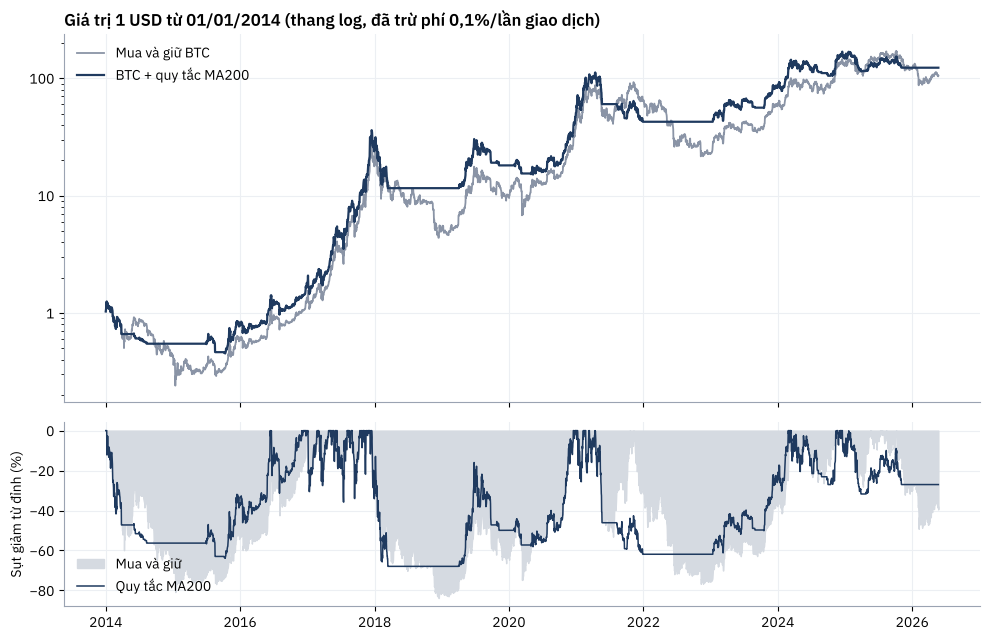

In [17]:
equity = (1 + bt).cumprod()
dd = equity / equity.cummax() - 1
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax = axes[0]
ax.plot(equity.index, equity['Mua và giữ BTC'], color=GREY, lw=1.3, label='Mua và giữ BTC')
ax.plot(equity.index, equity['BTC + quy tắc MA200'], color=NAVY, lw=1.6, label='BTC + quy tắc MA200')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: f'{y:,.0f}'))
ax.legend(frameon=False)
ax.set_title('Giá trị 1 USD từ 01/01/2014 (thang log, đã trừ phí 0,1%/lần giao dịch)')
ax = axes[1]
ax.fill_between(dd.index, dd['Mua và giữ BTC'] * 100, 0, color=LIGHT, label='Mua và giữ')
ax.plot(dd.index, dd['BTC + quy tắc MA200'] * 100, color=NAVY, lw=1.1, label='Quy tắc MA200')
ax.set_ylabel('Sụt giảm từ đỉnh (%)')
ax.legend(frameon=False, loc='lower left')
plt.tight_layout()
plt.savefig('figures/ma200.png', dpi=200, bbox_inches='tight')
plt.show()

In [18]:
# Trạng thái hiện tại của quy tắc
above = btc > ma200
last_switch = above[above != above.shift()].index[-1]
print(f'Giá BTC {btc.index[-1].date()}: {btc.iloc[-1]:,.0f} USD | MA200: {ma200.iloc[-1]:,.0f} USD')
print(f'Quy tắc đang {"GIỮ BTC" if above.iloc[-1] else "GIỮ TIỀN MẶT"} từ {last_switch.date()}')
print(f'Đỉnh lịch sử {btc.max():,.0f} USD ngày {btc.idxmax().date()}, giá hiện tại thấp hơn {1 - btc.iloc[-1] / btc.max():.0%}')

Giá BTC 2026-05-23: 76,620 USD | MA200: 80,679 USD
Quy tắc đang GIỮ TIỀN MẶT từ 2025-11-03
Đỉnh lịch sử 124,824 USD ngày 2025-10-06, giá hiện tại thấp hơn 39%


In [19]:
# Độ nhạy: kết quả có phụ thuộc vào con số 200 không?
rows = []
for n in [50, 100, 150, 200, 250, 300]:
    sig = (btc > btc.rolling(n).mean()).astype(int).shift(1)
    s = (sig * btc_ret - sig.diff().abs() * FEE).loc['2014-01-01':].dropna()
    p = perf(s)
    rows.append({'Số ngày MA': n, 'CAGR': p['CAGR'], 'Sụt giảm tối đa': p['Sụt giảm tối đa'], 'Sharpe': p['Sharpe (rf=0)']})
pd.DataFrame(rows).set_index('Số ngày MA')

,CAGR,Sụt giảm tối đa,Sharpe
Số ngày MA,,,
50,0.640,-0.627,1.286
100,0.592,-0.636,1.190
150,0.570,-0.644,1.149
200,0.474,-0.679,1.008
250,0.450,-0.735,0.961
300,0.483,-0.711,0.989


**Nhận xét:**
- Từ 2014, quy tắc MA200 cho CAGR tương đương mua và giữ (~47% so với ~46%/năm) nhưng **sụt giảm tối đa chỉ -68% thay vì -84%**, biến động giảm từ 68% xuống 52%. Lợi ích chính là giảm rủi ro, không phải tăng lợi nhuận.
- Kết quả **không ổn định theo giai đoạn**: 2018–2021 quy tắc thua (giá cắt lên xuống MA200 nhiều lần, mỗi lần mất phí và lỡ nhịp hồi), còn 2022–2026 thắng rõ (sụt giảm -32% so với -67%).
- Mọi mức từ 50 đến 300 ngày đều giảm sụt giảm tối đa so với mua và giữ (-63% đến -74% so với -84%), nên kết luận không phụ thuộc vào con số 200. MA50 cho kết quả tốt nhất trong quá khứ, nhưng chọn mức tốt nhất sau khi đã biết kết quả là overfitting; MA200 được giữ vì là mốc phổ biến chọn từ trước.
- Cuối dữ liệu, BTC (76.620 USD) nằm dưới MA200 (80.679 USD) từ 03/11/2025, nên quy tắc đang giữ tiền mặt và đã tránh được phần lớn nhịp giảm 39% từ đỉnh 124.824 USD (06/10/2025).
- Hạn chế: chưa tính thuế, trượt giá khi thị trường biến động mạnh, và lãi tiền gửi khi giữ tiền mặt.

## 7. On-chain: chỉ số MVRV có cho biết BTC rẻ hay đắt?

**MVRV = vốn hoá thị trường / vốn hoá thực (realized cap).** Vốn hoá thực định giá mỗi đồng BTC theo giá lần cuối nó được chuyển trên blockchain, gần đúng với giá vốn trung bình của người nắm giữ. MVRV < 1 nghĩa là trung bình người nắm giữ đang lỗ; MVRV > 3 nghĩa là đang lãi gấp 3.

Câu hỏi: lợi nhuận 1 năm sau của BTC khác nhau thế nào theo mức MVRV hôm nay?

In [20]:
chain = btc_chain.loc['2012-01-01':, ['PriceUSD', 'CapMVRVCur']].copy()
chain['fwd_1y'] = chain['PriceUSD'].shift(-365) / chain['PriceUSD'] - 1
mv = chain.dropna()
mv['Nhóm MVRV'] = pd.cut(mv['CapMVRVCur'], [0, 1, 1.5, 2, 2.5, 3, 10],
                        labels=['< 1', '1–1,5', '1,5–2', '2–2,5', '2,5–3', '> 3'])
mvrv_tbl = mv.groupby('Nhóm MVRV', observed=True).agg(
    so_ngay=('fwd_1y', 'size'),
    loi_nhuan_1y_trung_vi=('fwd_1y', 'median'),
    ty_le_lai=('fwd_1y', lambda s: (s > 0).mean()))
latest = btc_chain['CapMVRVCur'].dropna()
print(f'MVRV mới nhất ({latest.index[-1].date()}): {latest.iloc[-1]:.2f}')
mvrv_tbl

MVRV mới nhất (2026-05-23): 1.41


,so_ngay,loi_nhuan_1y_trung_vi,ty_le_lai
Nhóm MVRV,,,
< 1,662,0.981,0.991
"1–1,5",1256,1.144,0.838
"1,5–2",1489,1.241,0.669
"2–2,5",781,0.598,0.638
"2,5–3",411,0.220,0.608
> 3,293,-0.087,0.461


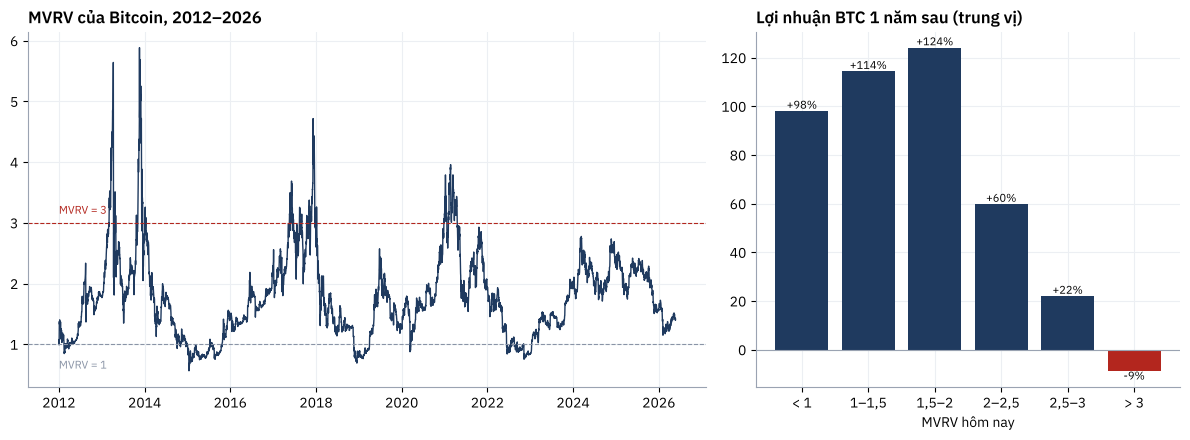

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
m = btc_chain['CapMVRVCur'].loc['2012':]
ax.plot(m.index, m, color=NAVY, lw=1)
ax.axhline(1, color=GREY, lw=0.8, ls='--')
ax.axhline(3, color=RED, lw=0.8, ls='--')
ax.text(m.index[0], 3.15, 'MVRV = 3', color=RED, fontsize=8)
ax.text(m.index[0], 0.6, 'MVRV = 1', color=GREY, fontsize=8)
ax.set_title('MVRV của Bitcoin, 2012–2026')
ax = axes[1]
vals = mvrv_tbl['loi_nhuan_1y_trung_vi'] * 100
b = ax.bar(vals.index.astype(str), vals, color=[NAVY if v > 0 else RED for v in vals])
ax.bar_label(b, fmt='%+.0f%%', fontsize=8)
ax.axhline(0, color='#9AA3B2', lw=0.8)
ax.set_xlabel('MVRV hôm nay')
ax.set_title('Lợi nhuận BTC 1 năm sau (trung vị)')
plt.tight_layout()
plt.savefig('figures/mvrv.png', dpi=200, bbox_inches='tight')
plt.show()

**Nhận xét:**
- Khi MVRV < 1 (người nắm giữ trung bình đang lỗ), BTC tăng trong 99% số trường hợp 1 năm sau (trung vị +98%). MVRV càng cao, tỷ lệ có lãi càng giảm: 84% ở vùng 1–1,5, 61% ở vùng 2,5–3 và chỉ 46% khi MVRV > 3, lúc đó trung vị **-9%**.
- MVRV cuối dữ liệu (23/05/2026) là **1,41**: thuộc vùng trung tính, chưa rẻ như các đáy (<1) nhưng xa vùng quá nóng (>3).
- **Cẩn trọng:** các ngày liền nhau có cửa sổ 1 năm chồng lên nhau, nên 662 ngày MVRV < 1 thực chất chỉ là khoảng 4 giai đoạn đáy độc lập. Đây là tín hiệu tham khảo cho tỷ trọng, không phải điểm mua bán chính xác.

## 8. Thanh khoản: quy mô stablecoin (USDT + USDC)

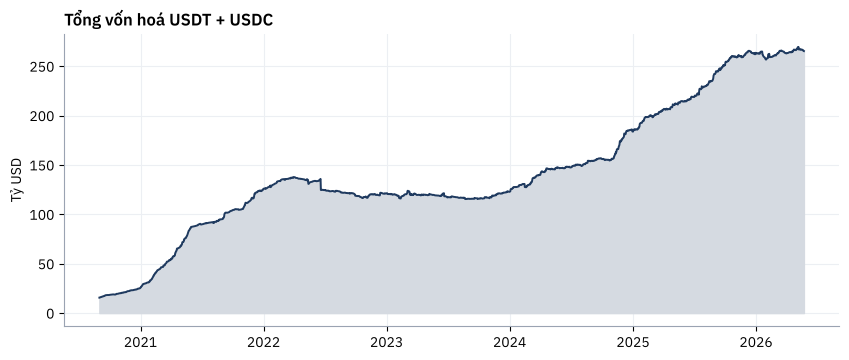

2020-09-01: 16 tỷ USD -> 2026-05-23: 265 tỷ USD


In [22]:
stable = (prices['USDT_cap'] + prices['USDC_cap']).loc['2020-09-01':] / 1e9
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(stable.index, stable, color=LIGHT)
ax.plot(stable.index, stable, color=NAVY, lw=1.4)
ax.set_ylabel('Tỷ USD')
ax.set_title('Tổng vốn hoá USDT + USDC')
plt.savefig('figures/stablecoins.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'{stable.index[0].date()}: {stable.iloc[0]:,.0f} tỷ USD -> {stable.index[-1].date()}: {stable.iloc[-1]:,.0f} tỷ USD')

Stablecoin là "tiền mặt" trong hệ sinh thái crypto. Quy mô USDT + USDC tăng từ khoảng 16 tỷ USD (09/2020) lên khoảng 265 tỷ USD (05/2026), kể cả qua năm 2022 sụp đổ chỉ giảm nhẹ. Với góc nhìn đầu tư mạo hiểm (VC), đây là mảng có nhu cầu sử dụng thật (thanh toán, chuyển tiền quốc tế) ổn định hơn nhiều so với giá token.

## 9. Kết luận và khuyến nghị

| Câu hỏi | Trả lời từ dữ liệu |
|---|---|
| Rủi ro crypto lớn đến đâu? | BTC biến động ~58%/năm, từng sụt 77%; altcoin sụt 70–98%. Chỉ nên phân bổ phần tiền chịu được mất 80%. |
| Đa dạng hoá sang altcoin có giúp gì? | Không giảm rủi ro (tương quan tăng khi thị trường sập). Lợi nhuận vượt trội chỉ đến từ 2 đồng trong năm 2021; bắt đầu sau 06/2021 thì BTC thắng mọi rổ. |
| Có quy tắc đơn giản nào giảm sụt giảm? | MA200 giữ CAGR tương đương nhưng giảm sụt giảm tối đa từ -84% xuống -68% (2014–2026); kém hiệu quả khi thị trường đi ngang. |
| On-chain có giúp định giá? | MVRV < 1 lịch sử là vùng mua tốt, > 3 là vùng rủi ro cao; hiện tại 1,41 (trung tính). |

**Khuyến nghị cho một danh mục muốn có crypto:**
1. Lấy BTC làm lõi (ví dụ 70–100% phần crypto); altcoin, nếu có, xem như khoản đầu cơ nhỏ và chấp nhận có thể mất trắng.
2. Dùng quy tắc trend (MA200) hoặc giới hạn tỷ trọng và tái cân bằng định kỳ để kiểm soát sụt giảm, thay vì cố đoán đáy.
3. Tăng tỷ trọng khi MVRV thấp, giảm khi MVRV > 3; theo dõi quy mô stablecoin như chỉ báo dòng tiền vào thị trường.

**Hạn chế:** thiên lệch sống sót ở rổ altcoin; dữ liệu đến 23/05/2026; backtest chưa tính thuế, trượt giá, lãi tiền mặt; kết quả quá khứ không đảm bảo tương lai. Đây là phân tích học thuật, không phải lời khuyên đầu tư.